In [2]:
#loading necessary libraries

import pandas as pd
from sklearn.model_selection import train_test_split

### Data loading and cleaning

In [4]:
#data loading
df= pd.read_csv("../../Datasets/heart_disease.csv", na_values= "?").dropna()
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [6]:
#normalizition
df['target']= (df['num']>0).astype(int)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


In [7]:
#feature selection
X= df.drop(columns= ['num', 'target'])
y= df['target']

In [9]:
#train_test_split

X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", X_train.shape[0], "test:", X_test.shape[0])

train: 237 test: 60


### Train SVM classifiere

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report


In [14]:
#.fit(X_train) calculates the mean and standard deviation of each training feature. It learns the numbers needed for scaling, but doesn't transform the data yet.
scaler= StandardScaler().fit(X_train)

#Scale the training data using z= x-mean/std
X_train_s= scaler.transform(X_train)

#Scale the training data using z= x-mean/std
X_test_s= scaler.transform(X_test)

#This creates a Support Vector Classifier using the RBF kernel.
#The RBF kernel allows SVM to learn a nonlinear decision boundary when a straight boundary isn't sufficient.
svm= SVC(kernel= 'rbf')

#traing the model
svm.fit(X_train_s, y_train)

#classification_report (comparing predictions with actual values)
report= classification_report(y_test, svm.predict(X_test_s), target_names= ['no disease', 'disease'])
print(report)

              precision    recall  f1-score   support

  no disease       0.83      0.91      0.87        32
     disease       0.88      0.79      0.83        28

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60



### Train Decision Tree Classifier

In [20]:
from sklearn.tree import DecisionTreeClassifier

model= DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

#classification report
y_pred= model.predict(X_test)
report= classification_report(y_test, y_pred, target_names=['no disease', 'disease'])

print(report)

print("Decision Tree - train_accuracy:", round(model.score(X_train, y_train), 3)) 
print("Decision Tree - test_accuracy:", round(model.score(X_test, y_test), 3)) 

              precision    recall  f1-score   support

  no disease       0.71      0.75      0.73        32
     disease       0.69      0.64      0.67        28

    accuracy                           0.70        60
   macro avg       0.70      0.70      0.70        60
weighted avg       0.70      0.70      0.70        60

Decision Tree - train_accuracy: 1.0
Decision Tree - test_accuracy: 0.7


#### our Train Decision Tree Classifier model did not perform well so we are gonna change some defalut vlaues, to see if our models accuracy gonna chnage or not

In [21]:
#STARTING WITH max_depth= 3 {this is random we are just trail and error to see any differrence it makes or not}

model= DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

#classification report
y_pred= model.predict(X_test)
report= classification_report(y_test, y_pred, target_names=['no disease', 'disease'])
print(report)

print("Decision Tree - train_accuracy:", round(model.score(X_train, y_train), 3)) 
print("Decision Tree - test_accuracy:", round(model.score(X_test, y_test), 3)) 

              precision    recall  f1-score   support

  no disease       0.81      0.81      0.81        32
     disease       0.79      0.79      0.79        28

    accuracy                           0.80        60
   macro avg       0.80      0.80      0.80        60
weighted avg       0.80      0.80      0.80        60

Decision Tree - train_accuracy: 0.844
Decision Tree - test_accuracy: 0.8


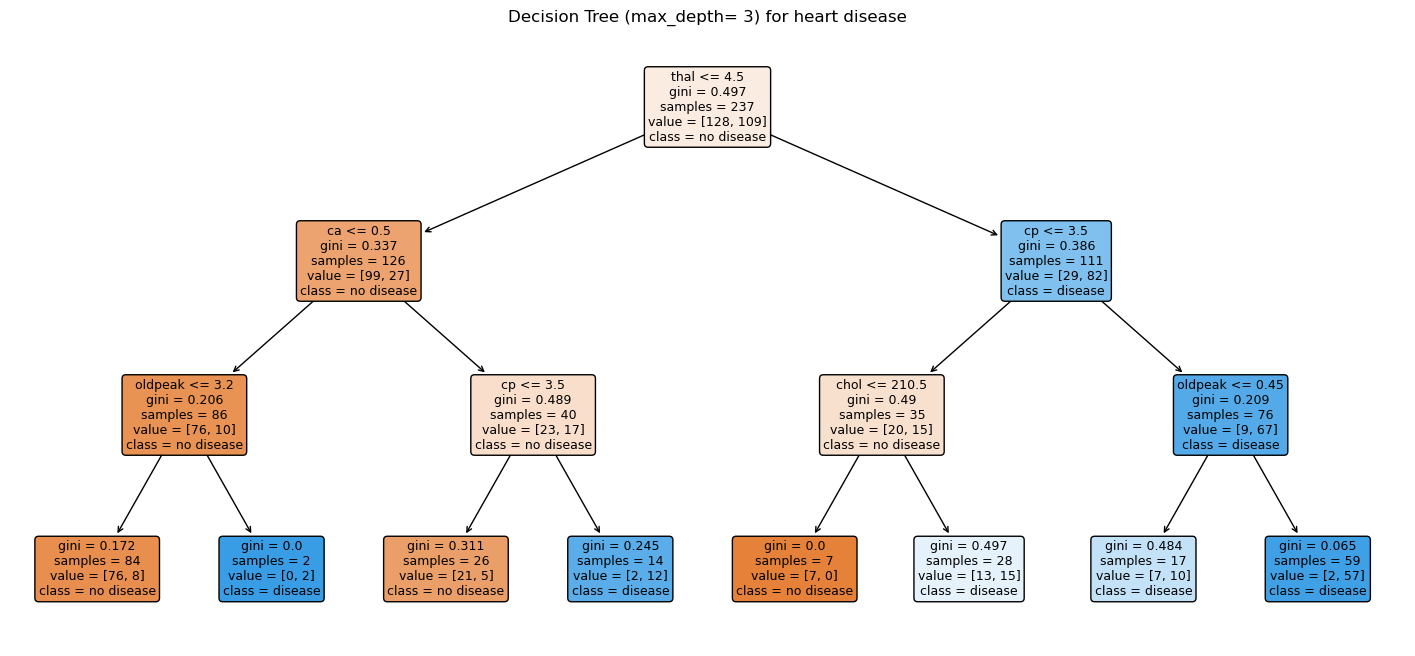

In [22]:
#visualizing tree

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))
plot_tree(model, feature_names=X.columns, class_names=['no disease', 'disease'], filled= True, rounded= True, fontsize=9)
plt.title("Decision Tree (max_depth= 3) for heart disease")
plt.show()

In [25]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num', 'target'],
      dtype='object')

In [23]:
#feature importance

model.feature_importances_

array([0.        , 0.        , 0.27202949, 0.        , 0.04890251,
       0.        , 0.        , 0.        , 0.        , 0.10599595,
       0.        , 0.07917658, 0.49389547])

In [27]:
import pandas as pd

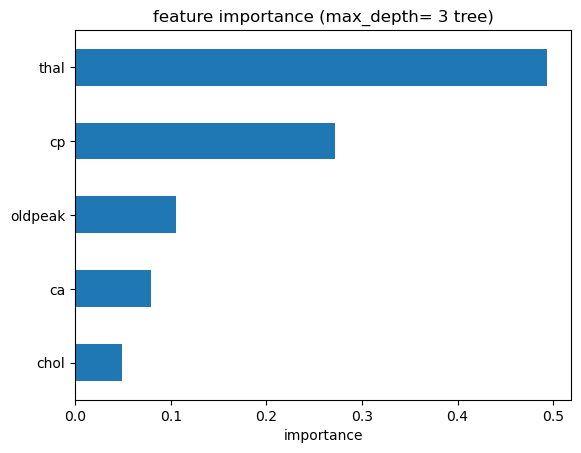

In [29]:
#ploting this data
importances= pd.Series(model.feature_importances_, index= X.columns)
importances= importances[importances>0].sort_values()

importances.plot(kind= 'barh')
plt.xlabel("importance")
plt.title("feature importance (max_depth= 3 tree)")
plt.show()